[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# A Station Atlas &middot; Solutions


One way to do each task. Not the only way. If yours runs and does what was asked, yours is
right too.

In [1]:
from pathlib import Path
import shutil

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import pyogrio
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)

network = station_network()
districts = forecast_districts()
scratch = Path("scratch")
scratch.mkdir(exist_ok=True)
print("geopandas", gpd.__version__, "| pyogrio", pyogrio.__version__, "|", len(countries), "countries,",
      len(network), "made-up stations,", len(districts), "made-up districts")

geopandas 1.2.0 | pyogrio 0.13.0 | 5 countries, 300 made-up stations, 8 made-up districts


The worked examples' atlas, rebuilt here from the made-up stations and districts so that each answer runs on its own.

In [2]:
countries_m = countries.to_crs(25833)
named_m = named.to_crs(25833)
atlas = gpd.GeoDataFrame(
    network, geometry=gpd.points_from_xy(network["longitude"], network["latitude"]), crs=4326
).to_crs(25833)
atlas = gpd.sjoin(atlas, districts, how="left").drop(columns="index_right")
norway = countries_m.loc[countries_m["ADMIN"] == "Norway", "geometry"].iloc[0]
neighbors = countries_m.loc[countries_m["ADMIN"] != "Norway", "geometry"].union_all()
coast = norway.boundary.difference(neighbors.buffer(1_000))
atlas["coast_km"] = (atlas.distance(coast) / 1000).round(1)
atlas = gpd.sjoin_nearest(atlas, named_m[["name", "geometry"]], how="left", distance_col="named_m")
atlas = atlas.drop(columns="index_right")
atlas["named_km"] = (atlas.pop("named_m") / 1000).round(1)
summary = atlas.groupby("district").agg(stations=("station", "size"))
district_atlas = districts.merge(summary, left_on="district", right_index=True, how="left")
district_atlas["stations"] = district_atlas["stations"].fillna(0).astype(int)

**1.** Print the five stations closest to the coast, with their districts and distances.

In [3]:
atlas.nsmallest(5, "coast_km")[["station", "district", "coast_km"]]

,station,district,coast_km
3,NS004,Far North,0.3
75,NS076,West,0.3
275,NS276,West,0.4
210,NS211,North,0.5
100,NS101,West,0.7


`nsmallest` keeps the rows with the smallest distances, in order. Three of the five are in the West district.

**2.** For each owner, print how many of their stations stand within 10 km of the coast.

In [4]:
(atlas["coast_km"] < 10).groupby(atlas["owner"]).sum()

owner
airport     6
met        21
private    11
road       22
Name: coast_km, dtype: int64

The comparison gives `True` or `False` for each station, and summing it by owner counts the `True`s.

**3.** Find the station farthest from any named station, and print its id, its district, the named station nearest to it and the distance.

In [5]:
atlas.nlargest(1, "named_km")[["station", "district", "name", "named_km"]]

,station,district,name,named_km
232,NS233,Mid,Tromso,577.2


`named_km` is already the distance to the nearest named station, so the largest value is the station farthest from all of them.

**4.** Add to `district_atlas` the share of each district's stations that stand within 10 km of the coast, and draw it as a map with three quantile classes.

 district  near_coast
    South        0.12
     East        0.00
     West        0.26
      Mid        0.14
    North        0.44
Far North        0.32
Northeast        0.31
 Svalbard         NaN


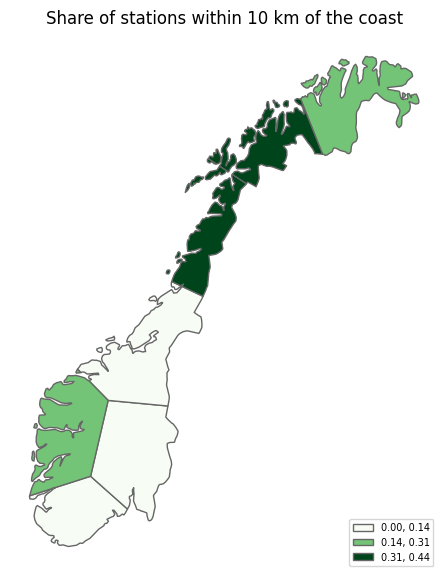

In [6]:
near_coast = (atlas["coast_km"] < 10).groupby(atlas["district"]).mean()
district_atlas["near_coast"] = district_atlas["district"].map(near_coast).round(2)
print(district_atlas[["district", "near_coast"]].to_string(index=False))

mainland = district_atlas[district_atlas["stations"] > 0]
fig, ax = plt.subplots(figsize=(6, 7))
mainland.plot(ax=ax, column="near_coast", scheme="Quantiles", k=3, cmap="Greens", edgecolor="0.4",
              legend=True, legend_kwds={"loc": "lower right", "fontsize": 7})
ax.set_axis_off()
ax.set_title("Share of stations within 10 km of the coast")
plt.show()

Svalbard has no stations, so its share is `NaN`, and the map leaves it out by drawing only the districts that have stations.

**5.** Write the named stations, in UTM zone 33N, to a GeoPackage of their own in `scratch` alongside a layer of the districts, and print the file's layers.

In [7]:
own = scratch / "named.gpkg"
named_m.to_file(own, layer="named")
districts.to_file(own, layer="districts")
print(pyogrio.list_layers(own))

[['named' 'Point']
 ['districts' 'MultiPolygon']]


Each `to_file` call with a new layer name adds a layer to the file.

This last cell is the notebook's cleanup. It removes the scratch folder and everything the answers wrote into it.

In [8]:
shutil.rmtree(scratch)
print("scratch folder left:", scratch.exists())

scratch folder left: False


---

&#8592; **Back to:** [A Station Atlas](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/13-a-station-atlas.ipynb)  &nbsp;&middot;&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)
